# 01 — Data Understanding: Mengenal Spotify Songs Dataset

**Tujuan:** *pahami dulu, baru mengolah.* Notebook ini menjawab pertanyaan:
seperti apa bentuk datanya, kolom apa saja yang ada, dan **apa saja masalah kualitas
data** yang harus diperbaiki di notebook berikutnya.

Aturan penting project ini:
- `data/raw/` **hanya dibaca, tidak pernah diubah** — ini sumber kebenaran.
- Semua keputusan cleaning ditulis beserta alasannya, bukan cuma kodenya.

Dataset: **Top 2000 lagu** dengan fitur audio dari Spotify API (danceability, energy,
valence, tempo, dll.) — populer untuk belajar analisis musik digital.

## 1. Persiapan: muat library dan dataset

Kenapa `pandas`, `seaborn`, `matplotlib`? Pandas untuk manipulasi tabel,
matplotlib + seaborn untuk grafik. Selama tahap memahami data kita belum butuh
Plotly/Streamlit — itu untuk dashboard nanti.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gaya visual konsisten untuk semua notebook
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

RAW_PATH = "../data/raw/songs_normalize.csv"

df = pd.read_csv(RAW_PATH)
print("Dataset berhasil dimuat dari", RAW_PATH)
print("Bentuk (baris, kolom):", df.shape)

Dataset berhasil dimuat dari ../data/raw/songs_normalize.csv
Bentuk (baris, kolom): (2000, 18)


## 2. Lihat 5 baris pertama

Sebelum analisis apa pun, intip isinya. Perhatikan `genre` bisa berisi beberapa genre
sekaligus (mis. `"rock, pop"`) — itu berarti datanya perlu diperlakukan khusus nanti.

In [2]:
df.head()

,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop


## 3. Tipe data tiap kolom

`info()` menunjukkan tipe data dan jumlah nilai tidak-null sekaligus.
Kita cari: kolom teks (object), kolom angka, dan apakah ada kolom yang ternyata
tipenya tidak sesuai harapan.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   artist            2000 non-null   str    
 1   song              2000 non-null   str    
 2   duration_ms       2000 non-null   int64  
 3   explicit          2000 non-null   bool   
 4   year              2000 non-null   int64  
 5   popularity        2000 non-null   int64  
 6   danceability      2000 non-null   float64
 7   energy            2000 non-null   float64
 8   key               2000 non-null   int64  
 9   loudness          2000 non-null   float64
 10  mode              2000 non-null   int64  
 11  speechiness       2000 non-null   float64
 12  acousticness      2000 non-null   float64
 13  instrumentalness  2000 non-null   float64
 14  liveness          2000 non-null   float64
 15  valence           2000 non-null   float64
 16  tempo             2000 non-null   float64
 17  genre 

## 4. Statistik deskriptif kolom numerik

`describe()` memberi gambaran sebaran: nilai minimum, maksimum, rata-rata, kuartil.
Dari sini kita sudah bisa menduga masalah data, misalnya `popularity` yang punya nilai 0
berarti "tidak ada data popularity" atau memang lagu tak populer — perlu diperiksa.

**Cara baca:** kolom fitur audio (danceability s/d valence) semestinya berada di
rentang 0–1; `key` 0–11 (12 nada dasar); `mode` 0/1; `tempo` dalam BPM; `loudness`
dalam dB (nilainya negatif).

In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
duration_ms,2000.0,228748.124,39136.569,113000.000,203580.000,223279.500,248133.000,484146.000
year,2000.0,2009.494,5.860,1998.000,2004.000,2010.000,2015.000,2020.000
popularity,2000.0,59.872,21.336,0.000,56.000,65.500,73.000,89.000
danceability,2000.0,0.667,0.140,0.129,0.581,0.676,0.764,0.975
energy,2000.0,0.720,0.153,0.055,0.622,0.736,0.839,0.999
key,2000.0,5.378,3.615,0.000,2.000,6.000,8.000,11.000
loudness,2000.0,-5.512,1.933,-20.514,-6.490,-5.285,-4.168,-0.276
mode,2000.0,0.554,0.497,0.000,0.000,1.000,1.000,1.000
speechiness,2000.0,0.104,0.096,0.023,0.040,0.060,0.129,0.576
acousticness,2000.0,0.129,0.173,0.000,0.014,0.056,0.176,0.976


## 5. Cek missing value

Kabar baik: dataset ini ternyata **tanpa null sama sekali**. Tapi "tanpa null" bukan
berarti "tanpa masalah" — lihat §6–§8 untuk masalah yang lebih halus.

In [5]:
null_count = df.isna().sum()
print("Total nilai null per kolom:")
print(null_count.to_string())
print("\nTotal null di seluruh dataset:", null_count.sum())

Total nilai null per kolom:
artist              0
song                0
duration_ms         0
explicit            0
year                0
popularity          0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
genre               0

Total null di seluruh dataset: 0


## 6. Masalah #1 — kolom `genre` kotor dan multi-nilai

Dari `head()` terlihat dua masalah:

1. Ada nilai literal **`set()`** — sisa format Python yang bocor ke CSV; artinya
   genre tidak diketahui.
2. Banyak sel berisi **lebih dari satu genre** (`"pop, R&B"`). Untuk analisis
   "per genre" nanti, ini harus dipecah — tapi hati-hati: kalau langsung di-explode,
   satu lagu terhitung di beberapa genre (dobel hitung).

Strategi (dipakai di notebook 02):

- `set()` → `"Unknown"` (genre tidak diketahui),
- jadikan list genre per lagu (`genre_list`) + ambil genre pertama sebagai
  `primary_genre` untuk statistik per-lagu,
- sedangkan tabel khusus `genres_long` (satu baris = lagu × genre) untuk
  statistik per-genre.

Dengan begitu tidak ada informasi yang dibuang dan tidak ada yang terhitung dua kali
secara salah.

In [6]:
print("Jumlah nilai genre unik (mentah):", df["genre"].nunique())
print("\nJumlah lagu yang tiap genre muncul (setelah dipecah):")
genre_exploded = df["genre"].astype(str).str.split(",").explode().str.strip()
print(genre_exploded.value_counts().to_string())
print("\nJumlah lagu dengan genre 'set()' (tidak diketahui):", (df["genre"] == "set()").sum())
print("Jumlah lagu dengan lebih dari satu genre:", df["genre"].str.contains(",").sum())

Jumlah nilai genre unik (mentah): 59

Jumlah lagu yang tiap genre muncul (setelah dipecah):
genre
pop                  1633
hip hop               778
R&B                   452
Dance/Electronic      390
rock                  234
metal                  66
latin                  64
set()                  22
country                21
Folk/Acoustic          20
World/Traditional      10
easy listening          7
blues                   4
jazz                    2
classical               1

Jumlah lagu dengan genre 'set()' (tidak diketahui): 22
Jumlah lagu dengan lebih dari satu genre: 1279


## 7. Masalah #2 — `popularity` bernilai 0 mencurigakan

Popularity skala 0–100. Lagu-lagu dalam daftar "Top 2000" wajar punya popularity
yang tinggi; nilai **0** di antara lagu populer sangat tidak wajar dan biasanya
berarti **data popularity tidak tersedia**, bukan lagu paling tidak populer di dunia.

Keputusan: nilai 0 **tidak dihapus dan tidak diimputasi** (menebak popularity palsu
sama buruknya dengan membuang), cukup diberi tanda `is_popularity_missing` supaya
bisa dikecualikan dari rata-rata saat dibutuhkan.

popularity == 0 : 126 lagu
popularity <= 1 : 157 lagu

Sebaran popularity:


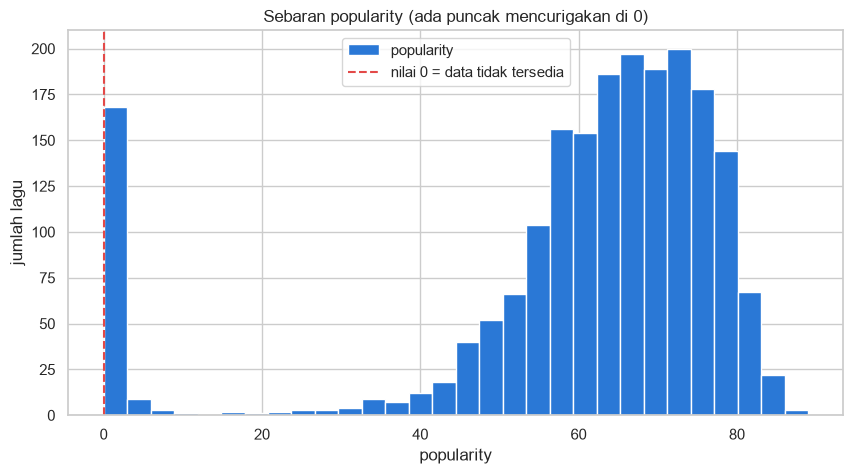

In [7]:
print("popularity == 0 :", (df["popularity"] == 0).sum(), "lagu")
print("popularity <= 1 :", (df["popularity"] <= 1).sum(), "lagu")
print("\nSebaran popularity:")
df["popularity"].plot(kind="hist", bins=30, color="#2a78d6", edgecolor="white")
plt.title("Sebaran popularity (ada puncak mencurigakan di 0)")
plt.xlabel("popularity"); plt.ylabel("jumlah lagu")
plt.axvline(0, color="#e34948", linestyle="--", label="nilai 0 = data tidak tersedia")
plt.legend(); plt.show()

## 8. Masalah #3 — duplikat

Jenis duplikat di sini ada dua, dan penanganannya berbeda:

- **Duplikat persis** (semua kolom sama): jelas sampah, dibuang.
- **Duplikat pasangan `artist` + `song`** tapi kolom lain beda (mis. tahun/popularity
  berbeda): biasanya lagu yang sama masuk daftar di tahun berbeda. Karena tiap lagu
  sebaiknya muncul sekali, kita simpan satu baris — pilih yang punya popularity
  paling tinggi (versi "utama"), sisanya dibuang dengan catatan.

Kenapa bukan "simpan yang pertama"? Karena baris dengan popularity 0 justru baris
yang datanya kurang lengkap; memilih popularity tertinggi membuat tiap baris
seinformasi mungkin.

In [8]:
print("Duplikat persis (semua kolom):", df.duplicated().sum())
print("Duplikat pasangan artist + song:", df.duplicated(subset=["artist", "song"]).sum())
print("\nContoh duplikat artist+song yang isinya berbeda:")
contoh = df[df.duplicated(subset=["artist", "song"], keep=False) & ~df.duplicated(keep=False)]
print(contoh.sort_values(["artist", "song"])[["artist", "song", "year", "popularity", "genre"]].head(10).to_string())

Duplikat persis (semua kolom): 59
Duplikat pasangan artist + song: 74

Contoh duplikat artist+song yang isinya berbeda:
                  artist                                    song  year  popularity              genre
1573        Alessia Cara                                    Here  2015           0           pop, R&B
1668        Alessia Cara                                    Here  2016          66           pop, R&B
1765             Cardi B                            Bodak Yellow  2017          59       hip hop, pop
1855             Cardi B                            Bodak Yellow  2018          72       hip hop, pop
174   Daniel Bedingfield  Gotta Get Thru This - D'N'D Radio Edit  2002          46                pop
268   Daniel Bedingfield  Gotta Get Thru This - D'N'D Radio Edit  2002          56                pop
1558               Drake                           Hotline Bling  2016          77  hip hop, pop, R&B
1652               Drake                           Hotline Bling

## 9. Validasi rentang nilai

Biar salah tipe/range langsung ketahuan: fitur audio harus 0–1, `key` 0–11, `mode`
0/1, `tempo` positif, `explicit` boolean. Hasilnya dipakai sebagai *assertion* di
notebook cleaning.

In [9]:
fitur_audio = ["danceability", "energy", "speechiness", "acousticness",
               "instrumentalness", "liveness", "valence"]

cek = {
    "fitur audio dalam 0-1": bool(df[fitur_audio].apply(lambda s: s.between(0, 1).all()).all()),
    "key dalam 0-11": bool(df["key"].between(0, 11).all()),
    "mode hanya 0/1": bool(df["mode"].isin([0, 1]).all()),
    "tempo > 0": bool((df["tempo"] > 0).all()),
    "explicit True/False": set(map(str, df["explicit"].unique())) <= {"True", "False"},
}
for nama, aman in cek.items():
    print(f"{nama}: {'AMAN' if aman else 'PERIKSA!'}")

print("\nRentang year:", df["year"].min(), "-", df["year"].max())

fitur audio dalam 0-1: AMAN
key dalam 0-11: AMAN
mode hanya 0/1: AMAN
tempo > 0: AMAN
explicit True/False: AMAN

Rentang year: 1998 - 2020


## 10. Pertanyaan analitis yang mau dijawab

EDA (notebook 04) dan dashboard akan fokus menjawab:

1. **Seperti apa "formula lagu populer"?** Fitur audio mana yang berkorelasi dengan
   popularity tinggi (dan mana yang ternyata tidak berpengaruh)?
2. **Apa beda karakter audio antar-genre?** (mis. metal vs pop vs hip hop)
3. **Bagaimana tren suara musik dari 1998–2020?** Apakah benar lagu makin keras
   (loudness, energy naik) dan makin sedikit akustik?
4. **Bagaimana distribusi panjang lagu, tempo, dan mood (valence × energy)?**
5. **Artis mana yang paling sering muncul, dan apakah artis dengan banyak lagu juga
   punya rata-rata popularity tinggi?**
6. **Bagaimana proporsi lagu explicit berkembang seiring tahun/genre?**

## 11. Ringkasan temuan data understanding

| Aspek | Temuan | Aksi |
|---|---|---|
| Bentuk data | 2.000 lagu, 18 kolom | — |
| Missing value | Tidak ada null | — |
| `genre` | Literal `set()` (genre tak diketahui) + 1.279 lagu multi-genre | Ubah jadi `"Unknown"`, `genre_list`, `primary_genre`, tabel `genres_long` |
| `popularity = 0` | 126 lagu — data kemungkinan tidak tersedia | Tandai `is_popularity_missing`, jangan imputasi |
| Duplikat | 59 duplikat persis; 74 duplikat pasangan `artist`+`song` | Buang duplikat persis, sisanya simpan yang popularity tertinggi |
| Tipe data | `explicit` sudah boolean, `key`/`mode` masih kode angka | Tambah `key_name`, `mode_name` (notebook 03) |
| Rentang nilai | Semua fitur audio 0–1, tempo positif, year 1998–2020 | Divalidasi lagi dengan assert di notebook 02 |

**Kesimpulan:** data sudah cukup rapi untuk sebuah project analitik; pekerjaan
utamanya adalah **menormalkan genre, menangani duplikat & popularity 0**, lalu membuat
fitur turunan. Notebook 02 akan mengerjakan bagian itu.

## 12. Cerita tahap ini: "kelihatan rapi ≠ siap dipakai"

**Pola bercerita data analyst:** `Hook → Angka → Makna`. Tiga langkah yang dipakai
di seluruh project ini, dan bisa kamu pakai untuk tugas analisis apa pun.

**Cerita tahap ini (contoh):**

> *Hook:* "Dataset ini kelihatan rapi — tidak ada satu pun sel kosong. Tapi ternyata
> ada 126 lagu yang popularity-nya nol, padahal mereka ada di daftar Top 2000."
>
> *Angka:* "Ada 22 lagu tanpa genre (bertuliskan `set()`), 1.279 lagu punya lebih dari
> satu genre, dan 74 lagu muncul dua kali — 59 di antaranya kembar persis."
>
> *Makna:* "Jadi sebelum menghitung apa pun, ada 3 keputusan yang harus diambil
> lebih dulu. Kalau dilewat, semua rata-rata di halaman berikutnya jadi tidak bisa
> dipertanggungjawabkan."

**Latihan untuk kamu:** tutup notebook ini, lalu coba ceritakan temuan di atas ke
seorang teman dalam **30 detik** memakai pola Hook → Angka → Makna. Kalau dia paham
tanpa menatap tabel, storytelling-mu sudah berhasil.